In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [2]:
train=pd.read_csv("train.csv")
test=pd.read_csv("test.csv")

In [3]:
train.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
train.shape

(1460, 81)

In [5]:
train.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [7]:
train.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [8]:
train.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

In [9]:
missing=train.isnull().sum()
missing=missing[missing>0]
missing.sort_values(ascending=False)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtFinType1      37
BsmtCond          37
BsmtQual          37
MasVnrArea         8
Electrical         1
dtype: int64

In [10]:
num_cols=train.select_dtypes(include=['int64','float64']).columns
print("Number of numerical columns:",len(num_cols))
print(num_cols)

Number of numerical columns: 38
Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')


In [11]:
cat_cols=train.select_dtypes(include=['object']).columns
print("number of categorical columns:",len(cat_cols))
print(cat_cols)

number of categorical columns: 43
Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')


In [12]:
missing=train.isnull().sum()
missing_percent=(missing/len(train))*100
missing_df=pd.DataFrame({'Missing Values':missing,'Percentage':missing_percent})
missing_df=missing_df[missing_df['Missing Values']>0]
missing_df=missing_df.sort_values(by='Percentage',ascending=False)
missing_df

,Missing Values,Percentage
PoolQC,1453,99.520548
MiscFeature,1406,96.301370
Alley,1369,93.767123
Fence,1179,80.753425
MasVnrType,872,59.726027
FireplaceQu,690,47.260274
LotFrontage,259,17.739726
GarageType,81,5.547945
GarageYrBlt,81,5.547945
GarageFinish,81,5.547945


In [13]:
missing_df.index.tolist()

['PoolQC',
 'MiscFeature',
 'Alley',
 'Fence',
 'MasVnrType',
 'FireplaceQu',
 'LotFrontage',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'BsmtFinType2',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtCond',
 'BsmtQual',
 'MasVnrArea',
 'Electrical']

In [14]:
none_cols=['PoolQC',
 'MiscFeature',
 'Alley',
 'Fence',
 'MasVnrType',
 'FireplaceQu',
 'LotFrontage',
 'GarageType',
 'GarageYrBlt',
 'GarageFinish',
 'GarageQual',
 'GarageCond',
 'BsmtFinType2',
 'BsmtExposure',
 'BsmtFinType1',
 'BsmtCond',
 'BsmtQual',
 'MasVnrArea',
 'Electrical']
for col in none_cols:
    if col in train.columns:
        train[col]=train[col].fillna('None')

In [15]:
train[none_cols].isnull().sum()

PoolQC          0
MiscFeature     0
Alley           0
Fence           0
MasVnrType      0
FireplaceQu     0
LotFrontage     0
GarageType      0
GarageYrBlt     0
GarageFinish    0
GarageQual      0
GarageCond      0
BsmtFinType2    0
BsmtExposure    0
BsmtFinType1    0
BsmtCond        0
BsmtQual        0
MasVnrArea      0
Electrical      0
dtype: int64

In [16]:
train.select_dtypes(include=['int64','float64']).isnull().sum().sort_values(ascending=False)

Id               0
OpenPorchSF      0
KitchenAbvGr     0
TotRmsAbvGrd     0
Fireplaces       0
GarageCars       0
GarageArea       0
WoodDeckSF       0
EnclosedPorch    0
HalfBath         0
3SsnPorch        0
ScreenPorch      0
PoolArea         0
MiscVal          0
MoSold           0
YrSold           0
BedroomAbvGr     0
FullBath         0
MSSubClass       0
BsmtFinSF2       0
LotArea          0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
BsmtFinSF1       0
BsmtUnfSF        0
BsmtHalfBath     0
TotalBsmtSF      0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
SalePrice        0
dtype: int64

In [17]:
train.select_dtypes(include='object').isnull().sum().sort_values(ascending=False)

MSZoning         0
FireplaceQu      0
BsmtExposure     0
BsmtFinType1     0
BsmtFinType2     0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
KitchenQual      0
Functional       0
GarageType       0
LotFrontage      0
GarageYrBlt      0
GarageFinish     0
GarageQual       0
GarageCond       0
PavedDrive       0
PoolQC           0
Fence            0
MiscFeature      0
SaleType         0
BsmtCond         0
BsmtQual         0
Foundation       0
ExterCond        0
Street           0
Alley            0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
RoofStyle        0
RoofMatl         0
Exterior1st      0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
SaleCondition    0
dtype: int64

In [18]:
train.describe()

,Id,MSSubClass,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,BsmtFinSF1,BsmtFinSF2,BsmtUnfSF,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,10516.828082,6.099315,5.575342,1971.267808,1984.865753,443.639726,46.549315,567.240411,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,9981.264932,1.382997,1.112799,30.202904,20.645407,456.098091,161.319273,441.866955,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,223.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,383.500000,0.000000,477.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,712.250000,0.000000,808.000000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,5644.000000,1474.000000,2336.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


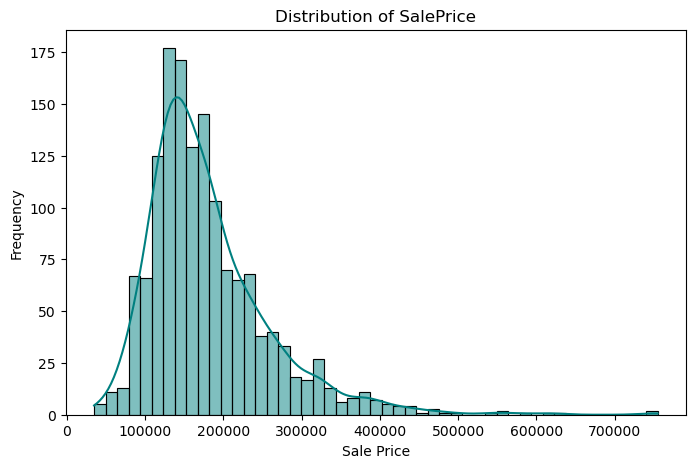

In [19]:
plt.figure(figsize=(8,5))
sns.histplot(train['SalePrice'],kde=True,color='teal')
plt.title("Distribution of SalePrice")
plt.xlabel("Sale Price")
plt.ylabel("Frequency")
plt.show()

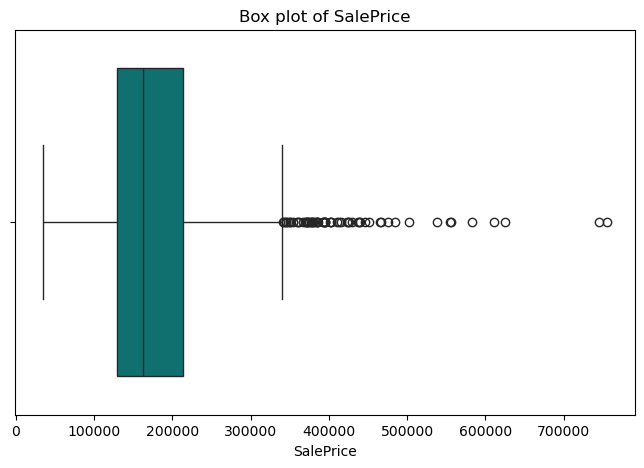

In [20]:
plt.figure(figsize=(8,5))
sns.boxplot(x=train['SalePrice'],color='teal')
plt.title("Box plot of SalePrice")
plt.show()

In [21]:
print(train['SalePrice'].skew())

1.8828757597682129


In [22]:
corr=train.corr(numeric_only=True)
saleprice_corr=corr["SalePrice"].sort_values(ascending=False)
print(saleprice_corr.head(15))

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Fireplaces      0.466929
BsmtFinSF1      0.386420
WoodDeckSF      0.324413
2ndFlrSF        0.319334
Name: SalePrice, dtype: float64


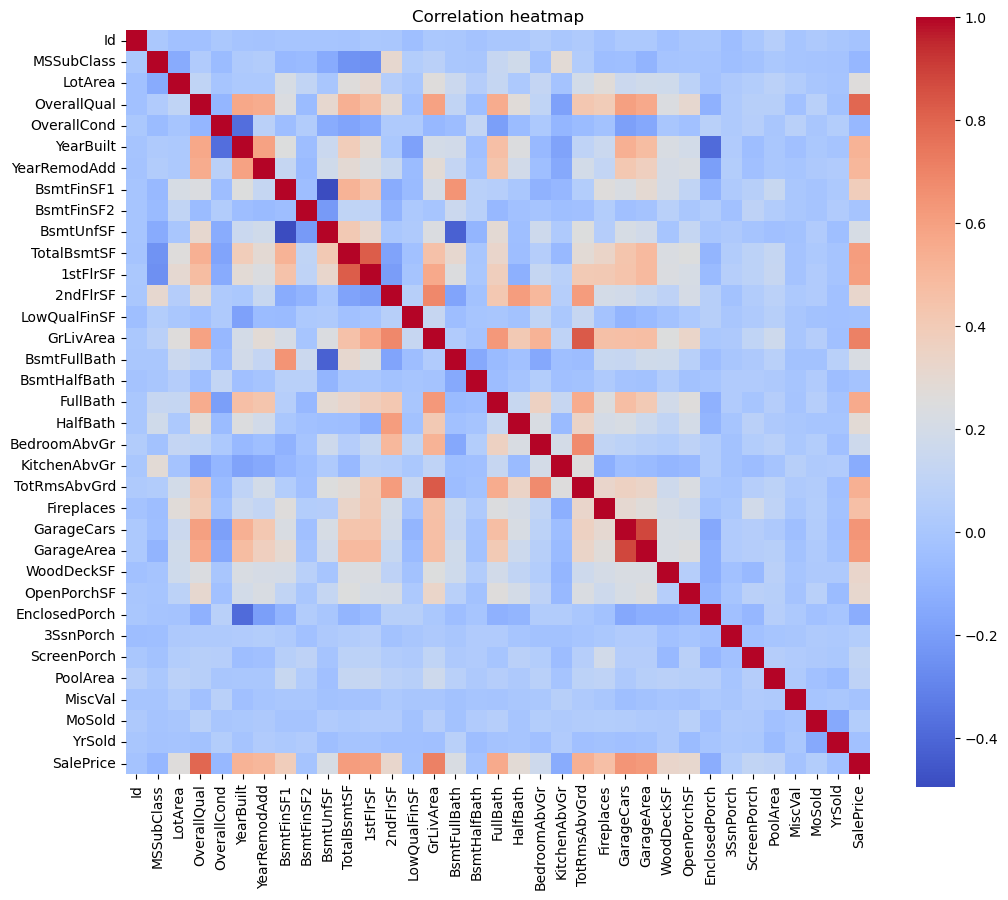

In [23]:
plt.figure(figsize=(12,10))
sns.heatmap(corr,cmap="coolwarm",square=True)
plt.title("Correlation heatmap")
plt.show()

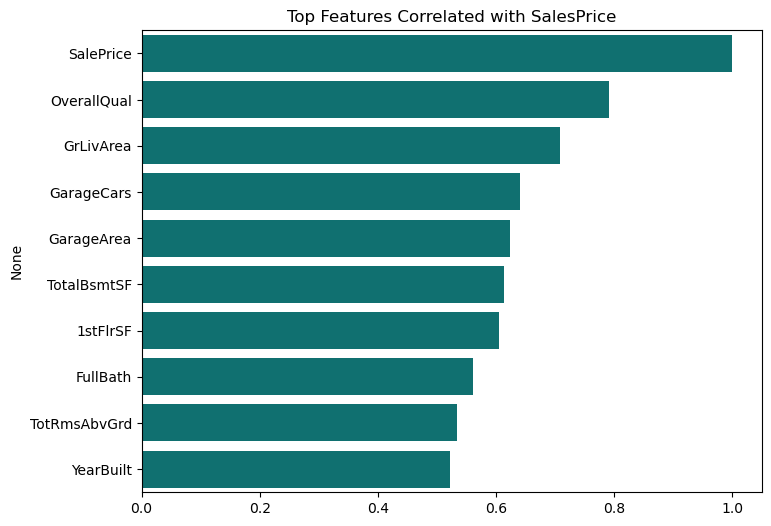

In [24]:
top_corr=corr['SalePrice'].sort_values(ascending=False).head(10)
plt.figure(figsize=(8,6))
sns.barplot(
    x=top_corr.values,
    y=top_corr.index,color='teal')
plt.title("Top Features Correlated with SalesPrice")
plt.show()

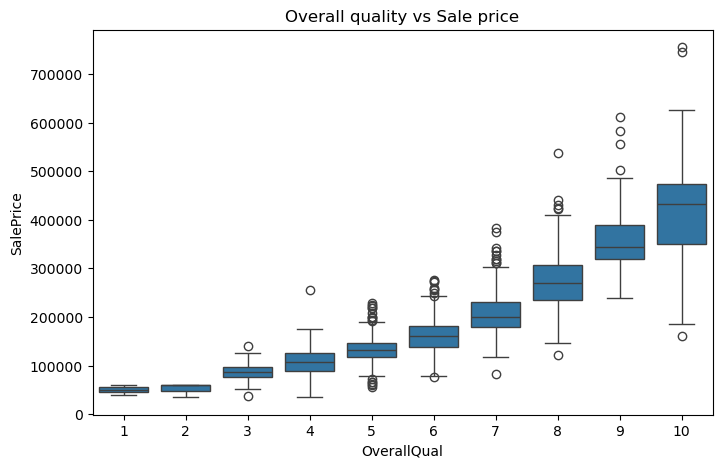

In [25]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=train,
    x='OverallQual',
    y='SalePrice'
)
plt.title("Overall quality vs Sale price")
plt.show()

Text(0.5, 1.0, 'Ground Living Area vs Sale Price')

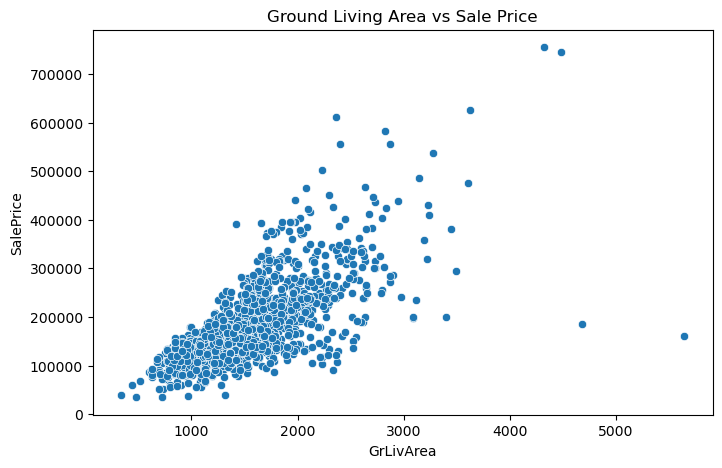

In [26]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=train,
    x="GrLivArea",y="SalePrice")
plt.title("Ground Living Area vs Sale Price")

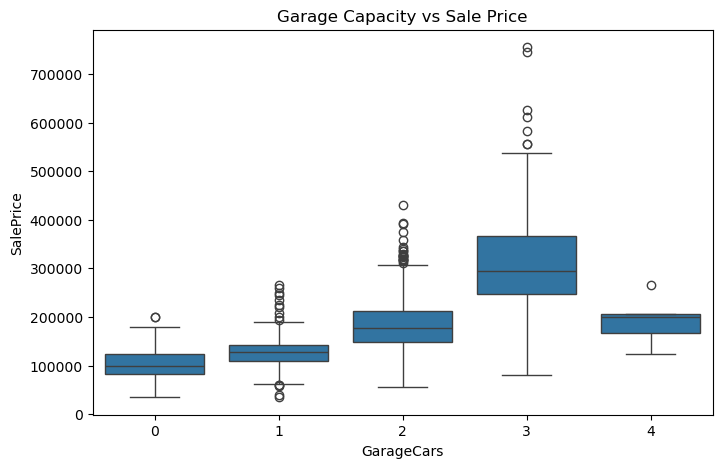

In [27]:
plt.figure(figsize=(8,5))
sns.boxplot(
    data=train,x="GarageCars",y="SalePrice")
plt.title("Garage Capacity vs Sale Price")
plt.show()

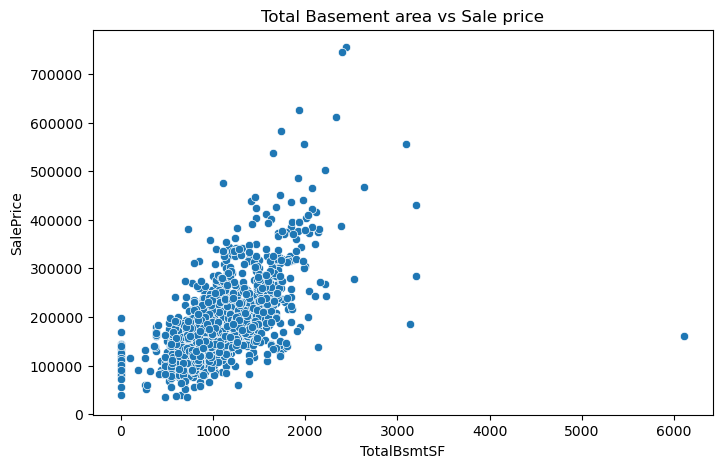

In [28]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=train,
    x="TotalBsmtSF",
    y="SalePrice")
plt.title("Total Basement area vs Sale price")
plt.show()

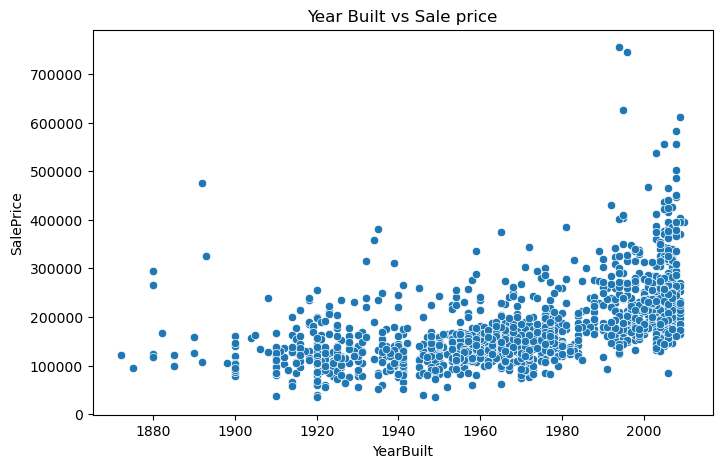

In [29]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    data=train,
    x="YearBuilt",
    y="SalePrice")
plt.title("Year Built vs Sale price")
plt.show()

In [30]:
x=train.drop('SalePrice',axis=1)
y=train['SalePrice']

In [31]:
print(x.shape)

(1460, 80)


In [32]:
print(y.shape)

(1460,)


In [33]:
x=pd.get_dummies(x,drop_first=True)

In [34]:
x.shape

(1460, 792)

In [35]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,
                                               y,
                                               test_size=0.2,
                                               random_state=42)

In [36]:
print("x_train:",x_train.shape)
print("x_test:",x_test.shape)
print("y_train:",y_train.shape)
print("x_test:",y_test.shape)

x_train: (1168, 792)
x_test: (292, 792)
y_train: (1168,)
x_test: (292,)


In [37]:
from sklearn.linear_model import LinearRegression
lr=LinearRegression()
lr.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [38]:
y_pred=lr.predict(x_test)

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error,r2_score
import numpy as np
lr_mae=mean_absolute_error(y_test,y_pred)
lr_mse=mean_squared_error(y_test,y_pred)
lr_rmse=np.sqrt(lr_mse)
lr_r2=r2_score(y_test,y_pred)
print("MAE:",lr_mae)
print("MSE:",lr_mse)
print("RMSE:",lr_rmse)
print("R2 score:",lr_r2)

MAE: 27102.177059983722
MSE: 1549271955.3835335
RMSE: 39360.79210818214
R2 score: 0.7980174618998785


In [40]:
y_pred=lr.predict(x_test)

In [41]:
print(y_pred[:10])

[163385.41725792 357134.12130622  60242.69387567 191788.47042141
 360389.98781131  82878.5548119  253669.9222686  138920.41823448
  60275.60958541 126048.97074633]


In [42]:
comparison=pd.DataFrame({
    "Actual":y_test,
    "Predicted":y_pred
})
comparison.head(10)

,Actual,Predicted
892,154500,163385.417258
1105,325000,357134.121306
413,115000,60242.693876
522,159000,191788.470421
1036,315500,360389.987811
614,75500,82878.554812
218,311500,253669.922269
1160,146000,138920.418234
649,84500,60275.609585
887,135500,126048.970746


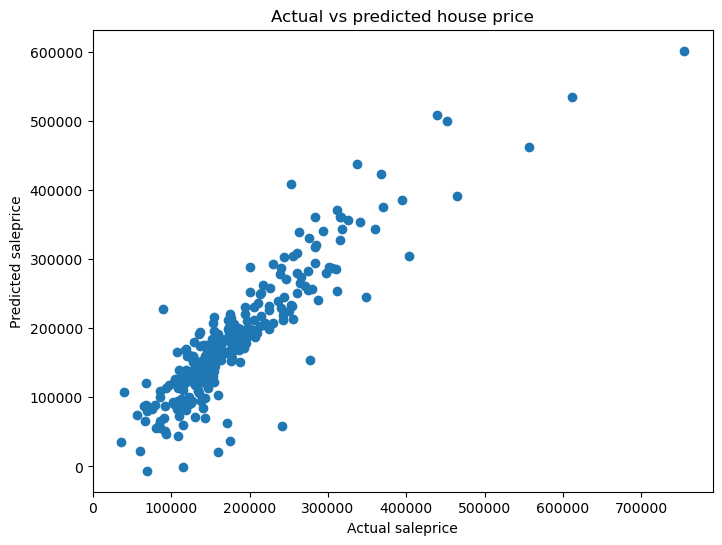

In [43]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred)
plt.xlabel("Actual saleprice")
plt.ylabel("Predicted saleprice")
plt.title("Actual vs predicted house price")
plt.show()

In [44]:
from sklearn.tree import DecisionTreeRegressor
dt=DecisionTreeRegressor(random_state=42)
dt.fit(x_train,y_train)
dt_pred=dt.predict(x_test)

In [45]:
dt

,criterion,'squared_error'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,ccp_alpha,0.0


In [46]:
from sklearn.metrics import mean_squared_error,r2_score
import numpy as np
dt_mae=mean_absolute_error(y_test,dt_pred)
dt_mse=mean_squared_error(y_test,dt_pred)
dt_rmse=np.sqrt(mean_squared_error(y_test,dt_pred))
dt_r2=r2_score(y_test,dt_pred)
print("MAE:",dt_mae)
print("MSE:",dt_mse)
print("RMSE:",dt_rmse)
print("R2 score:",dt_r2)

MAE: 26267.45205479452
MSE: 1577123832.239726
RMSE: 39713.01842267503
R2 score: 0.7943863416445112


In [47]:
result=pd.DataFrame({
    "Actual":y_test,
    "predicted":dt_pred
})
result.head(10)

,Actual,predicted
892,154500,158500.0
1105,325000,381000.0
413,115000,109900.0
522,159000,159000.0
1036,315500,374000.0
614,75500,86000.0
218,311500,205000.0
1160,146000,148500.0
649,84500,86000.0
887,135500,140000.0


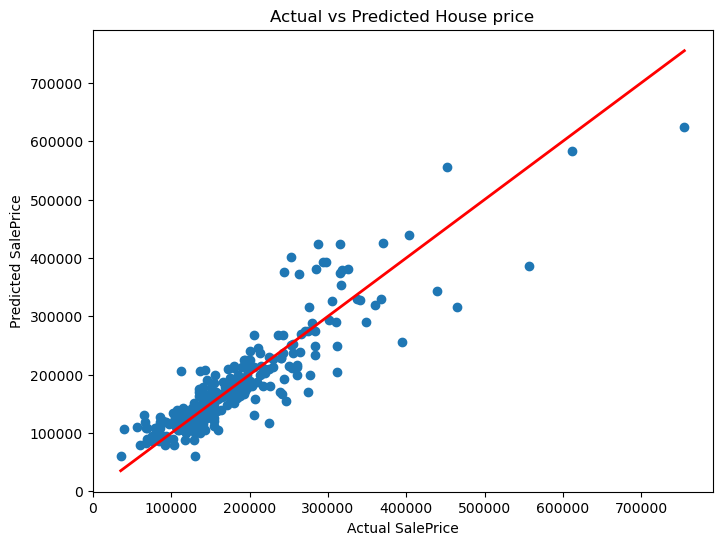

In [48]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,dt_pred)
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    color='red',
    linewidth=2
)
    
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted House price")
plt.show()

In [49]:
from sklearn.ensemble import RandomForestRegressor
rf=RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf.fit(x_train,y_train)
rf_pred=rf.predict(x_test)
                         

In [50]:
from sklearn.metrics import mean_squared_error,r2_score
import numpy as np
rf_mae=mean_absolute_error(y_test,rf_pred)
rf_mse=mean_squared_error(y_test,rf_pred)
rf_rmse=np.sqrt(mean_squared_error(y_test,rf_pred))
rf_r2=r2_score(y_test,rf_pred)
print("MAE:",rf_mae)
print("MSE:",rf_mse)
print("RMSE:",rf_rmse)
print("R2 score:",rf_r2)

MAE: 17777.583767123288
MSE: 833476767.4971191
RMSE: 28869.997705180358
R2 score: 0.8913375070389903


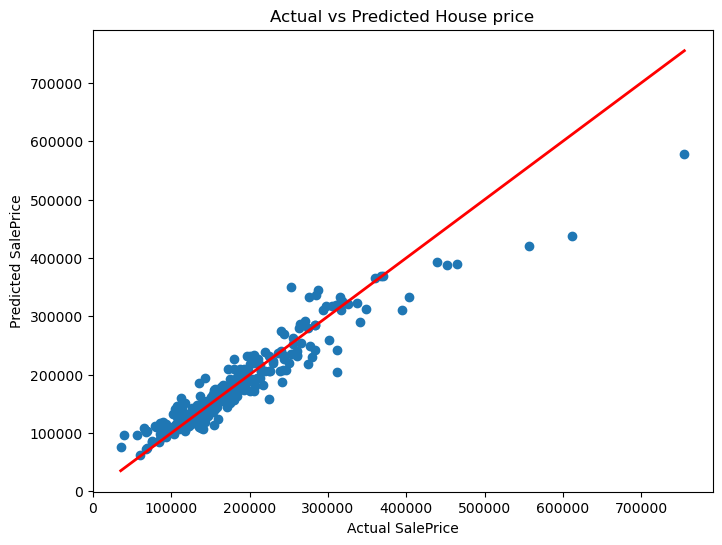

In [51]:
plt.figure(figsize=(8,6))
plt.scatter(y_test,rf_pred)
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()],
    color='red',
    linewidth=2
)
    
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.title("Actual vs Predicted House price")
plt.show()

In [52]:
comparison=pd.DataFrame({
    "Model":["Decision Tree",
             "Random Forest"],
             "R2 score":[
                r2_score(y_test,dt_pred),
                r2_score(y_test,rf_pred)],
            "MAE":[
                mean_absolute_error(y_test,dt_pred),
                mean_absolute_error(y_test,rf_pred)],
            "RMSE":[
                np.sqrt(mean_squared_error(y_test,dt_pred)),
                np.sqrt(mean_squared_error(y_test,rf_pred))
            ]
    
        })

In [53]:
comparison

,Model,R2 score,MAE,RMSE
0,Decision Tree,0.794386,26267.452055,39713.018423
1,Random Forest,0.891338,17777.583767,28869.997705


In [54]:
importance=pd.DataFrame({
    "Feature":x.columns,
    "Importance":rf.feature_importances_
})
importance=importance.sort_values(by="Importance",ascending=False)
importance.head(10)

,Feature,Importance
3,OverallQual,0.559594
14,GrLivArea,0.122207
10,TotalBsmtSF,0.034252
12,2ndFlrSF,0.034167
7,BsmtFinSF1,0.030707
11,1stFlrSF,0.027254
2,LotArea,0.017933
24,GarageArea,0.015779
5,YearBuilt,0.014306
23,GarageCars,0.012733


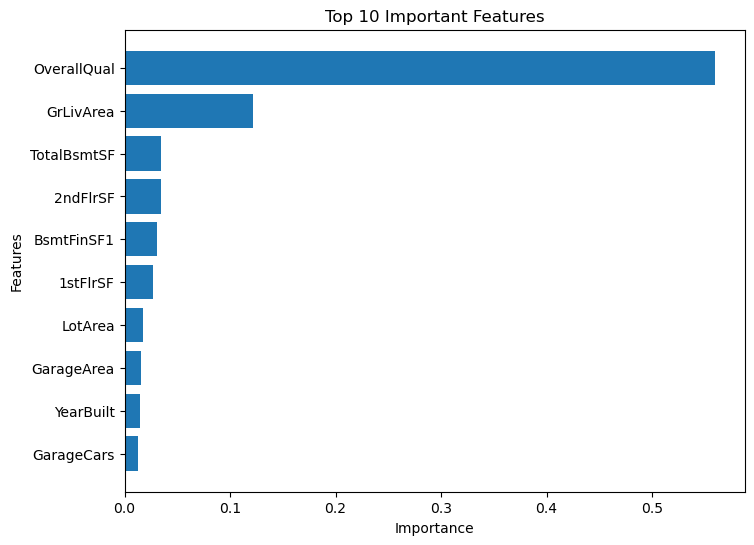

In [55]:
top10=importance.head(10)
plt.figure(figsize=(8,6))
plt.barh(top10["Feature"],
top10["Importance"])
plt.xlabel("Importance")
plt.ylabel("Features")
plt.title("Top 10 Important Features")
plt.gca().invert_yaxis()
plt.show()

In [56]:
results=pd.DataFrame({
    "Model":["Linear Regression","Decision Tree","Random Forest"],
    "R2 Score":[lr_r2,dt_r2,rf_r2],
    "MAE":[lr_mae,dt_mae,rf_mae],
    "RMSE":[lr_rmse,dt_rmse,rf_rmse]
        })
results

,Model,R2 Score,MAE,RMSE
0,Linear Regression,0.798017,27102.177060,39360.792108
1,Decision Tree,0.794386,26267.452055,39713.018423
2,Random Forest,0.891338,17777.583767,28869.997705


In [57]:
best_model=rf
sample=x_test.iloc[[0]]
prediction=best_model.predict(sample)
print("Predicted Price:",prediction[0])
print("Actual Price:",y_test.iloc[0])

Predicted Price: 140888.0
Actual Price: 154500


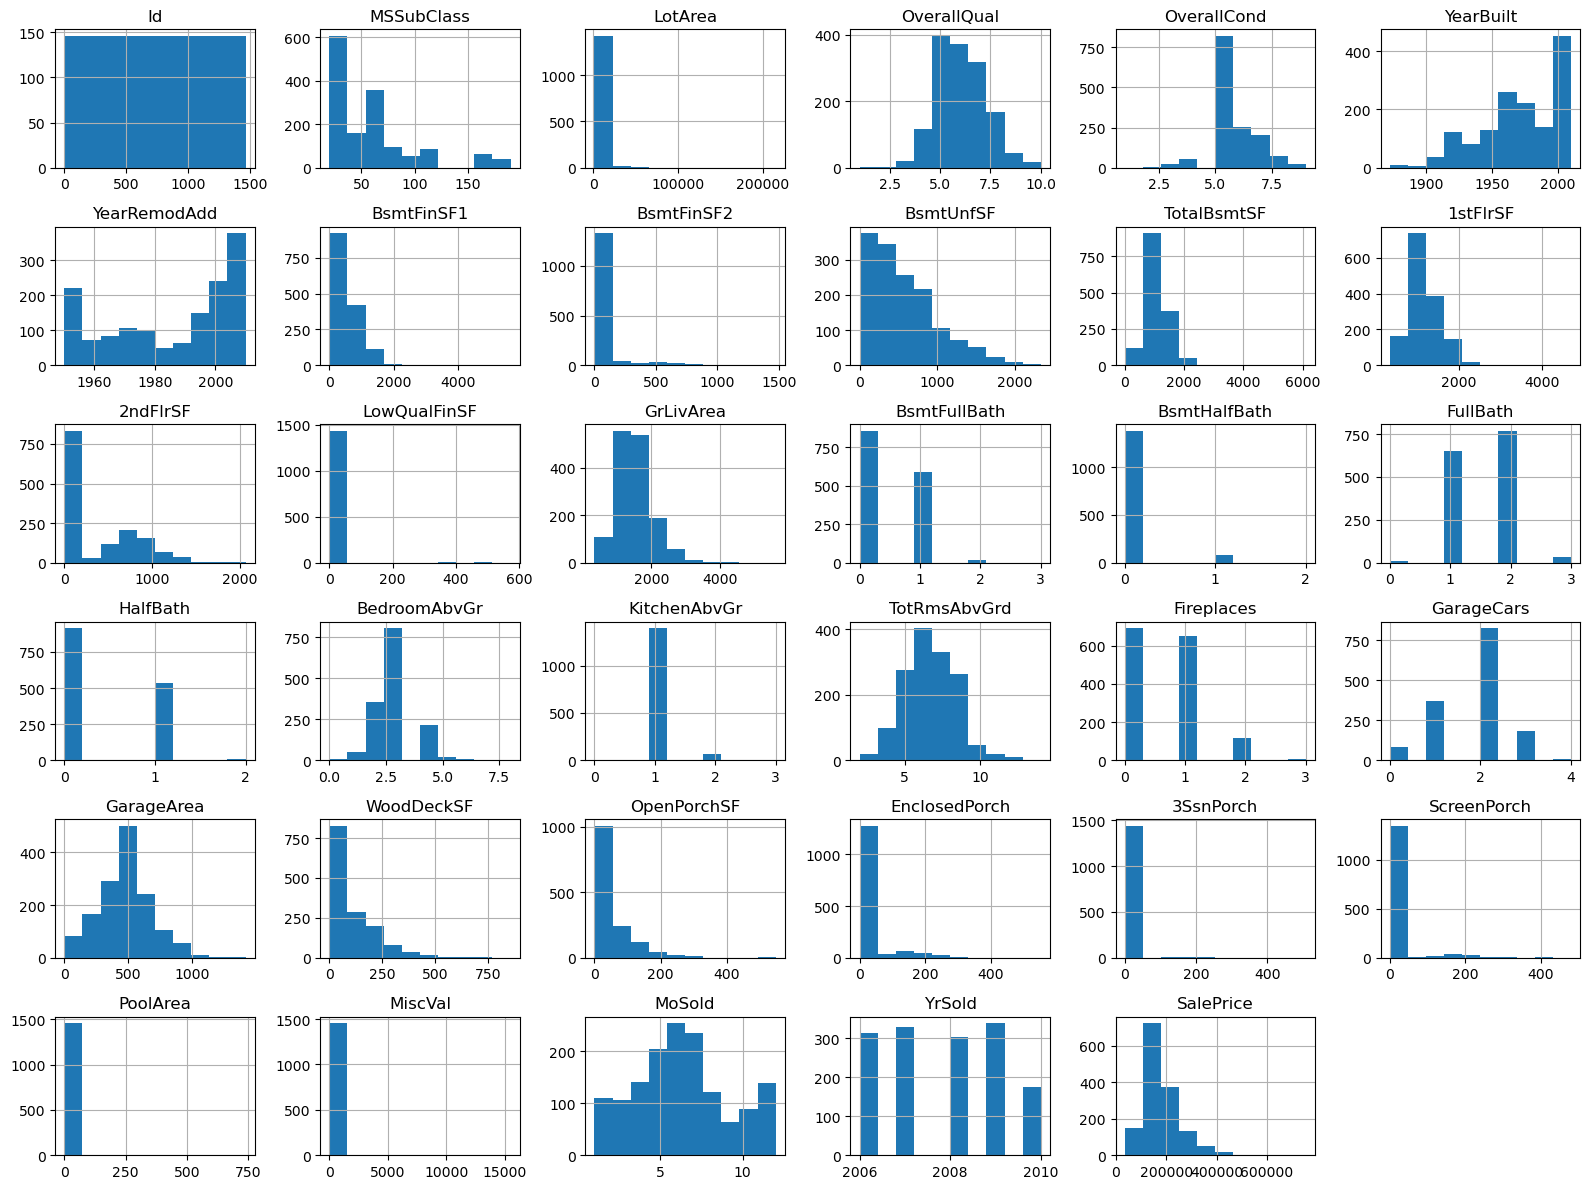

In [58]:
numeric_cols=train.select_dtypes(include="number").columns
train[numeric_cols].hist(figsize=(16,12))
plt.tight_layout()
plt.show()

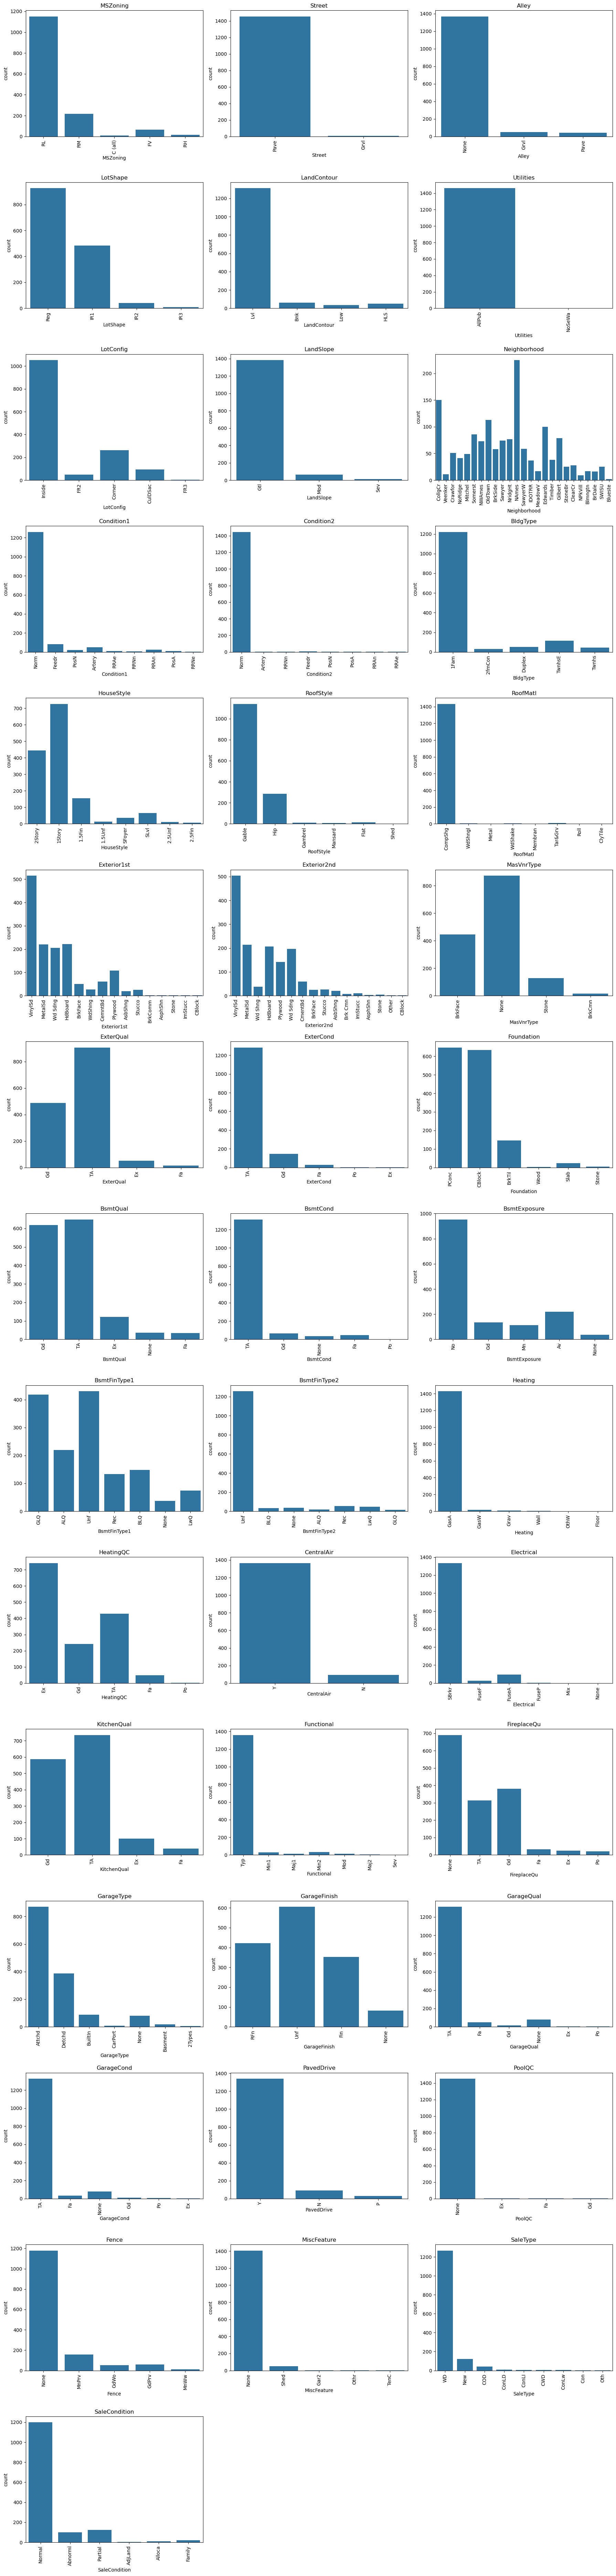

In [62]:
import math
n=len(cat_cols)
cols=3
rows=math.ceil(n/cols)

plt.figure(figsize=(18,5*rows))
for i in range(len(cat_cols)):
    plt.subplot(rows,cols,i+1)
    sns.countplot(data=train,x=cat_cols[i])
    plt.xticks(rotation=90)
    plt.title(cat_cols[i])
plt.tight_layout()
plt.show()

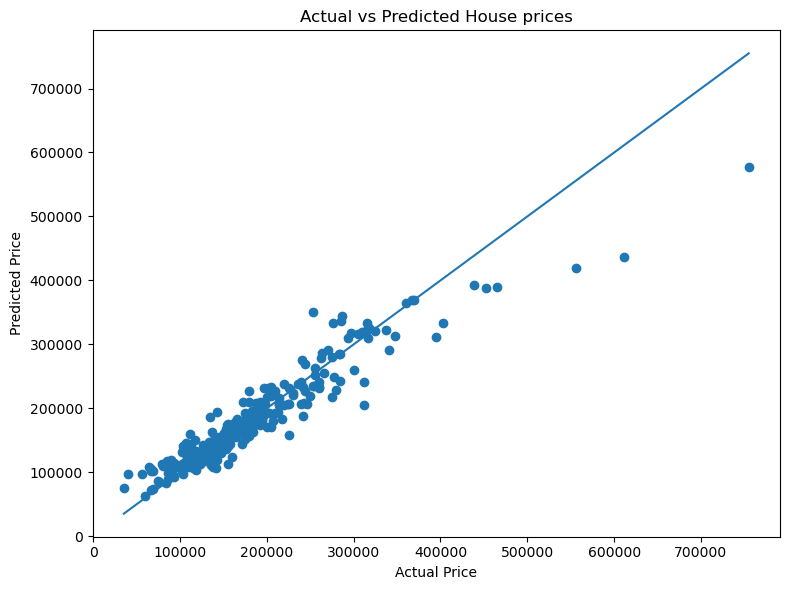

In [65]:
y_pred=best_model.predict(x_test)
plt.figure(figsize=(8,6))
plt.scatter(y_test,y_pred)
plt.plot(
    [y_test.min(),y_test.max()],
    [y_test.min(),y_test.max()]
)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted House prices")
plt.tight_layout()
plt.show()